In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/crime-data-up/2024-07-northamptonshire-street.csv
/kaggle/input/crime-data-up/2024-02-northamptonshire-street.csv
/kaggle/input/crime-data-up/2023-09-cumbria-street.csv
/kaggle/input/crime-data-up/2023-01-northamptonshire-street.csv
/kaggle/input/crime-data-up/2023-11-leicestershire-street.csv
/kaggle/input/crime-data-up/2024-09-cumbria-street.csv
/kaggle/input/crime-data-up/2024-03-leicestershire-street.csv
/kaggle/input/crime-data-up/2024-04-northamptonshire-street.csv
/kaggle/input/crime-data-up/2024-05-leicestershire-street.csv
/kaggle/input/crime-data-up/2024-08-northamptonshire-street.csv
/kaggle/input/crime-data-up/2023-04-northamptonshire-street.csv
/kaggle/input/crime-data-up/2023-06-bedfordshire-street.csv
/kaggle/input/crime-data-up/2024-01-leicestershire-street.csv
/kaggle/input/crime-data-up/2024-09-bedfordshire-street.csv
/kaggle/input/crime-data-up/2024-05-northamptonshire-street.csv
/kaggle/input/crime-data-up/2023-01-bedfordshire-street.csv
/kaggle/input/

# Activity 1

In [ ]:
!pip install pyspark

In [ ]:
# starting the spark session and config.
from pyspark import SparkConf, SparkContext
from pyspark.sql import SparkSession, SQLContext
spark = SparkSession.builder.master("local[2]").appName("dat").getOrCreate()
sc = spark.sparkContext
#create an instance of SQLContext
sqlContext = SQLContext(spark)

/usr/local/lib/python3.12/dist-packages/pyspark/sql/context.py:113: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


In [ ]:
# Import libraries and other functions
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from io import StringIO
from collections import namedtuple
from pyspark.sql import Row
from pyspark.sql.types import *
from pyspark.sql.functions import *
import csv

In [ ]:
# Creating a dataFrame directly for the Bedfordshire, Cumbria, Leicestershire and Nottinghamshire Cities of UK crime csv file
# Data source is https://data.police.uk/data/

BCLN_Crime = spark.read.option("header", "true").option("delimiter", ",")\
.option("inferSchema", "true").\
csv("/kaggle/input/crime-data-up")

In [ ]:
BCLN_Crime.printSchema()

root
 |-- Crime ID: string (nullable = true)
 |-- Month: timestamp (nullable = true)
 |-- Reported by: string (nullable = true)
 |-- Falls within: string (nullable = true)
 |-- Longitude: double (nullable = true)
 |-- Latitude: double (nullable = true)
 |-- Location: string (nullable = true)
 |-- LSOA code: string (nullable = true)
 |-- LSOA name: string (nullable = true)
 |-- Crime type: string (nullable = true)
 |-- Last outcome category: string (nullable = true)
 |-- Context: string (nullable = true)



In [ ]:
BCLN_Crime.show(n = 5, truncate = False)

+----------------------------------------------------------------+-------------------+---------------------+---------------------+---------+---------+----------------------------+---------+-------------------------+----------------------------+------------------------------------------+-------+
|Crime ID                                                        |Month              |Reported by          |Falls within         |Longitude|Latitude |Location                    |LSOA code|LSOA name                |Crime type                  |Last outcome category                     |Context|
+----------------------------------------------------------------+-------------------+---------------------+---------------------+---------+---------+----------------------------+---------+-------------------------+----------------------------+------------------------------------------+-------+
|e952aee9bec4f3f9e64497ac4796dc41798e60a97d8e5d051a8ce9d47b9b2cf6|2023-05-01 00:00:00|Leicestershire Police|Leic

In [ ]:
BCLN_Crime.printSchema()

root
 |-- Crime ID: string (nullable = true)
 |-- Month: timestamp (nullable = true)
 |-- Reported by: string (nullable = true)
 |-- Falls within: string (nullable = true)
 |-- Longitude: double (nullable = true)
 |-- Latitude: double (nullable = true)
 |-- Location: string (nullable = true)
 |-- LSOA code: string (nullable = true)
 |-- LSOA name: string (nullable = true)
 |-- Crime type: string (nullable = true)
 |-- Last outcome category: string (nullable = true)
 |-- Context: string (nullable = true)



## Data Cleaning

For the cleaning part i will remove the null values in Crime ID column because our Crime ID contains the unique values, We can not fill values by our own.

In [ ]:
# our total number of values in dataset
print(BCLN_Crime.count())

570274


In [ ]:
# Let us remove null values from Crime ID
BCLN_Crime_cleaned = BCLN_Crime.filter(col("Crime ID").isNotNull())
BCLN_Crime_cleaned.count()

496726

# Analyzing data with Spark SQL

In [ ]:
# register BCLN_Crime_cleaned df as a temporory SQL view

BCLN_Crime_cleaned.createOrReplaceTempView("cleaned_crime_data")

#verify via running a simple qury
spark.sql(" select * from cleaned_crime_data limit 3").show(truncate = False)


+----------------------------------------------------------------+-------------------+---------------------+---------------------+---------+---------+----------------------------+---------+-------------------------+----------------------------+---------------------------+-------+
|Crime ID                                                        |Month              |Reported by          |Falls within         |Longitude|Latitude |Location                    |LSOA code|LSOA name                |Crime type                  |Last outcome category      |Context|
+----------------------------------------------------------------+-------------------+---------------------+---------------------+---------+---------+----------------------------+---------+-------------------------+----------------------------+---------------------------+-------+
|e952aee9bec4f3f9e64497ac4796dc41798e60a97d8e5d051a8ce9d47b9b2cf6|2023-05-01 00:00:00|Leicestershire Police|Leicestershire Police|-1.354336|53.081911|On or n

In [ ]:
spark.sql("describe cleaned_crime_data").show(truncate= False)

+---------------------+---------+-------+
|col_name             |data_type|comment|
+---------------------+---------+-------+
|Crime ID             |string   |NULL   |
|Month                |timestamp|NULL   |
|Reported by          |string   |NULL   |
|Falls within         |string   |NULL   |
|Longitude            |double   |NULL   |
|Latitude             |double   |NULL   |
|Location             |string   |NULL   |
|LSOA code            |string   |NULL   |
|LSOA name            |string   |NULL   |
|Crime type           |string   |NULL   |
|Last outcome category|string   |NULL   |
|Context              |string   |NULL   |
+---------------------+---------+-------+



In [ ]:
spark.sql("""
    select
        count(case when `Crime ID` is null then 1 end) as `Crime ID`,
        count(case when `Month` is null then 1 end) as `Month`,
        count(case when `Reported by` is null then 1 end) as `Reported by`,
        count(case when `Falls within` is null then 1 end) as `Falls within`,
        count(case when `Location` is null then 1 end) as `Location`,
        count(case when `Crime type` is null then 1 end) as `Crime type`,
        count(case when `Last outcome category` is null then 1 end) as `Last outcome category`
     from cleaned_crime_data""").show()

+--------+-----+-----------+------------+--------+----------+---------------------+
|Crime ID|Month|Reported by|Falls within|Location|Crime type|Last outcome category|
+--------+-----+-----------+------------+--------+----------+---------------------+
|       0|    0|          0|           0|       0|         0|                    0|
+--------+-----+-----------+------------+--------+----------+---------------------+



#### Total number of crimes reported each month.

In [ ]:
monthly_crime_counts_sql = spark.sql("select date_format(Month, 'yyyy-MM') as Month_str, count(*) as count from cleaned_crime_data group by Month_str order by Month_str asc")
monthly_crime_counts_sql.show()

+---------+-----+
|Month_str|count|
+---------+-----+
|  2023-01|20332|
|  2023-02|20022|
|  2023-03|21970|
|  2023-04|21117|
|  2023-05|22153|
|  2023-06|21863|
|  2023-07|20931|
|  2023-08|20419|
|  2023-09|20884|
|  2023-10|20869|
|  2023-11|19713|
|  2023-12|19186|
|  2024-01|19549|
|  2024-02|19153|
|  2024-03|20626|
|  2024-04|20327|
|  2024-05|21798|
|  2024-06|21714|
|  2024-07|21682|
|  2024-08|21116|
+---------+-----+
only showing top 20 rows



## Frequency of each crime type

In [ ]:
crime_type_distribution_sql = spark.sql("select `crime type`, COUNT (*) as count from cleaned_crime_data group by `Crime type` order by count desc")
crime_type_distribution_sql.show()

+--------------------+------+
|          crime type| count|
+--------------------+------+
|Violence and sexu...|213889|
|Criminal damage a...| 47849|
|        Public order| 46201|
|         Other theft| 40583|
|         Shoplifting| 39466|
|       Vehicle crime| 33702|
|            Burglary| 23874|
|               Drugs| 18542|
|         Other crime| 12647|
|Possession of wea...|  6192|
|       Bicycle theft|  5366|
|             Robbery|  4810|
|Theft from the pe...|  3605|
+--------------------+------+



## Grouping crimes by "Reported by" police

In [ ]:
reporting_authority_counts_sql = spark.sql("select `Reported by`, count(*) as count from cleaned_crime_data group by `Reported by` order by count desc")
reporting_authority_counts_sql.show()

+--------------------+------+
|         Reported by| count|
+--------------------+------+
|Leicestershire Po...|198266|
|Northamptonshire ...|122089|
| Bedfordshire Police|103006|
|Cumbria Constabulary| 73365|
+--------------------+------+



### Top 10 crime locations LSOA

In [ ]:
top_10_lsoa_crimes_cleaned = BCLN_Crime_cleaned.groupBy("LSOA name").count().orderBy(col("count").desc()).limit(10)
top_10_lsoa_crimes_cleaned.show(truncate=False)

+--------------------------+-----+
|LSOA name                 |count|
+--------------------------+-----+
|NULL                      |11889|
|Leicester 041E            |7915 |
|West Northamptonshire 032E|2655 |
|Leicester 041D            |2465 |
|Luton 023A                |2160 |
|Charnwood 003A            |2093 |
|Leicester 040F            |2035 |
|Luton 023C                |2002 |
|Blaby 006C                |1993 |
|Carlisle 006B             |1934 |
+--------------------------+-----+



## Extract year from the Month

In [ ]:
BCLN_Crime_cleaned = BCLN_Crime_cleaned.withColumn ("Year", date_format(col("Month"),"yyyy"))
BCLN_Crime_cleaned.select("Month", "Year").show(7)

+-------------------+----+
|              Month|Year|
+-------------------+----+
|2023-05-01 00:00:00|2023|
|2023-05-01 00:00:00|2023|
|2023-05-01 00:00:00|2023|
|2023-05-01 00:00:00|2023|
|2023-05-01 00:00:00|2023|
|2023-05-01 00:00:00|2023|
|2023-05-01 00:00:00|2023|
+-------------------+----+
only showing top 7 rows



## Crime Count Per year

In [ ]:
yearly_crime_counts = BCLN_Crime_cleaned.groupBy("Year").count().orderBy("Year", ascending = True)
yearly_crime_counts.show()

+----+------+
|Year| count|
+----+------+
|2023|249459|
|2024|247267|
+----+------+



# Visualization of data

### Converting data from Spark df to pandas df

In [ ]:
yearly_crime_counts_pd = yearly_crime_counts.toPandas()

/tmp/ipykernel_55/3071777754.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x = 'Year', y = 'count', data = yearly_crime_counts_pd , palette = 'viridis')


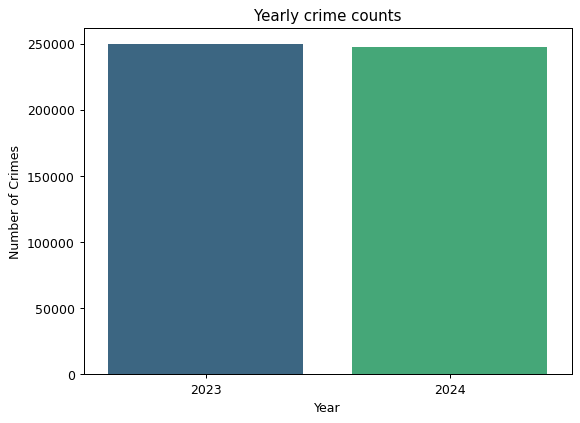

In [ ]:
plt.figure(figsize= (7,5), dpi = 90)
sns.barplot(x = 'Year', y = 'count', data = yearly_crime_counts_pd , palette = 'viridis')
plt.title('Yearly crime counts')
plt.xlabel('Year')
plt.ylabel('Number of Crimes')
plt.show()

## Yearly Crime count per City

In [ ]:
yearly_crime_counts_by_city = BCLN_Crime_cleaned.groupBy("Year", "Reported by").count().orderBy("Year", "Reported by")
yearly_crime_counts_by_city.show()

+----+--------------------+------+
|Year|         Reported by| count|
+----+--------------------+------+
|2023| Bedfordshire Police| 49764|
|2023|Cumbria Constabulary| 36244|
|2023|Leicestershire Po...|101868|
|2023|Northamptonshire ...| 61583|
|2024| Bedfordshire Police| 53242|
|2024|Cumbria Constabulary| 37121|
|2024|Leicestershire Po...| 96398|
|2024|Northamptonshire ...| 60506|
+----+--------------------+------+



In [ ]:
# converting to pandas df
yearly_crime_counts_by_city_pd = yearly_crime_counts_by_city.toPandas()

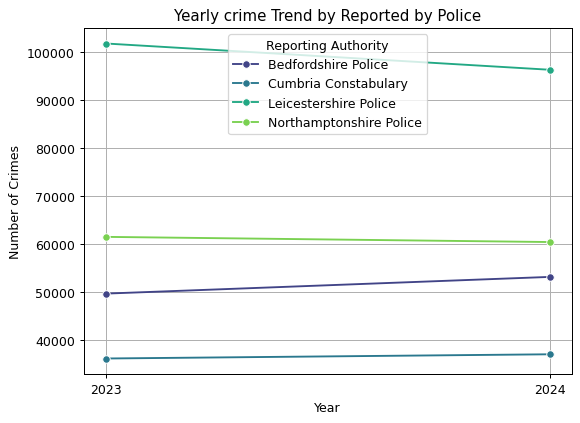

In [ ]:
plt.figure(figsize= (7,5), dpi = 90)
sns.lineplot(x = 'Year', y = 'count',hue = 'Reported by', data = yearly_crime_counts_by_city_pd ,marker = 'o', palette = 'viridis')
plt.title('Yearly crime Trend by Reported by Police')
plt.xlabel('Year')
plt.ylabel('Number of Crimes')
plt.legend(title = 'Reporting Authority')
plt.grid(True)
plt.show()

# Top 5 crimes of each police/city

In [ ]:
from pyspark.sql.window import Window
from pyspark.sql.functions import row_number

# unique reporting police/city
reporting_authorities = BCLN_Crime_cleaned.select('Reported by').distinct().rdd.flatMap(lambda x: x).collect()
# Prepare to store top crime types for each police/city
top_crime_types_by_authority = {}
for authority in reporting_authorities:
    print(f"\nTop 5 Crime Types for {authority}:")
    # Filter data for the current police/city
    authority_data = BCLN_Crime_cleaned.filter(col("Reported by") == authority)
    # Group by Crime type, count, and order by count des
    top_crime_types = authority_data.groupBy("Crime type").count().orderBy(col("count").desc()).limit(5)
    top_crime_types_by_authority[authority] = top_crime_types
    top_crime_types.show(truncate=False)


Top 5 Crime Types for Leicestershire Police:


+----------------------------+-----+
|Crime type                  |count|
+----------------------------+-----+
|Violence and sexual offences|81604|
|Public order                |22136|
|Criminal damage and arson   |19969|
|Other theft                 |16991|
|Shoplifting                 |14201|
+----------------------------+-----+


Top 5 Crime Types for Northamptonshire Police:


+----------------------------+-----+
|Crime type                  |count|
+----------------------------+-----+
|Violence and sexual offences|56160|
|Criminal damage and arson   |10648|
|Shoplifting                 |10564|
|Other theft                 |9441 |
|Vehicle crime               |8187 |
+----------------------------+-----+


Top 5 Crime Types for Bedfordshire Police:


+----------------------------+-----+
|Crime type                  |count|
+----------------------------+-----+
|Violence and sexual offences|40604|
|Shoplifting                 |10085|
|Vehicle crime               |10034|
|Public order                |9078 |
|Other theft                 |8793 |
+----------------------------+-----+


Top 5 Crime Types for Cumbria Constabulary:


+----------------------------+-----+
|Crime type                  |count|
+----------------------------+-----+
|Violence and sexual offences|35521|
|Criminal damage and arson   |8506 |
|Public order                |7287 |
|Other theft                 |5358 |
|Shoplifting                 |4616 |
+----------------------------+-----+



## Visualization

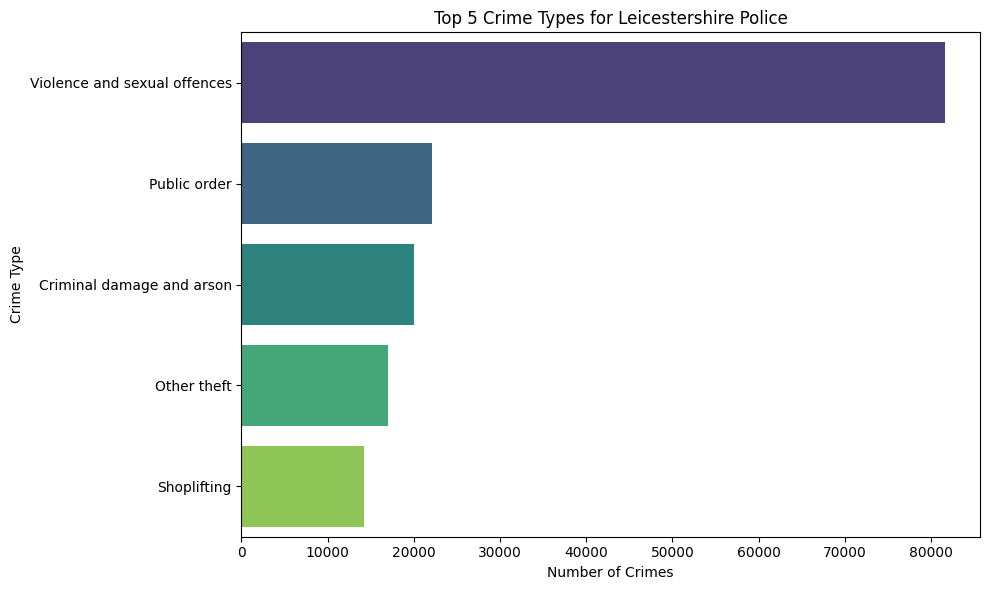

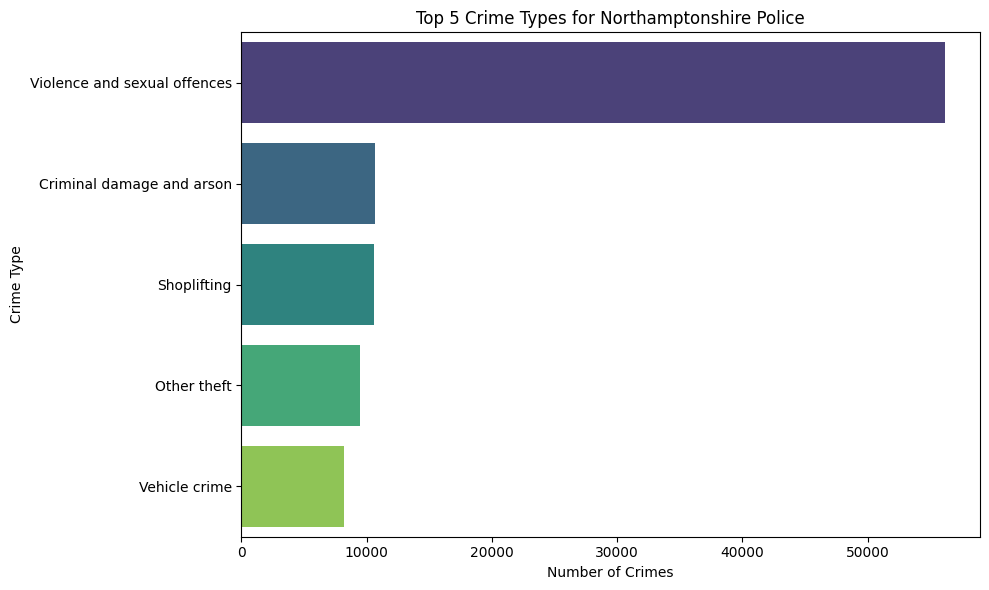

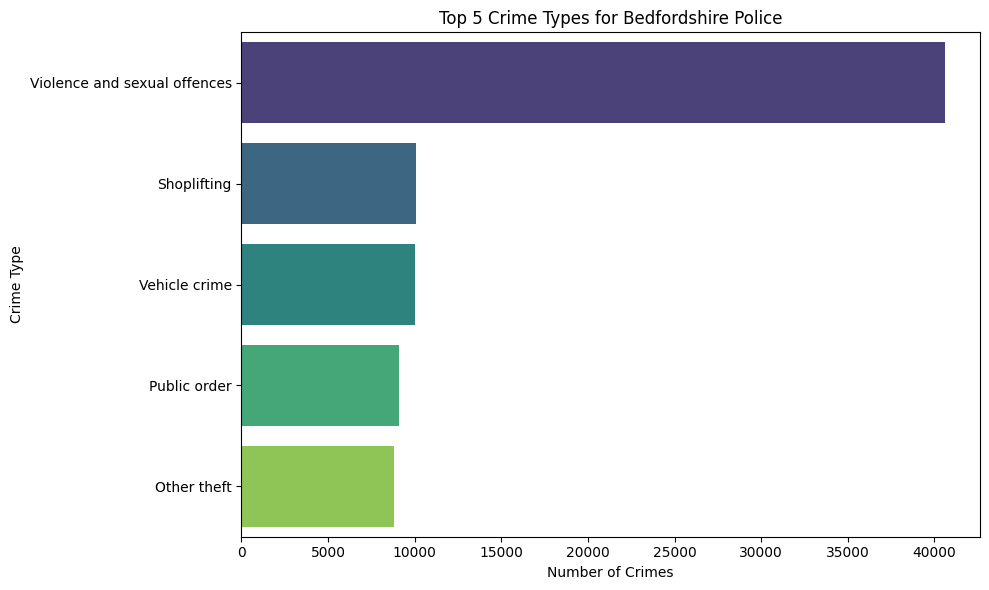

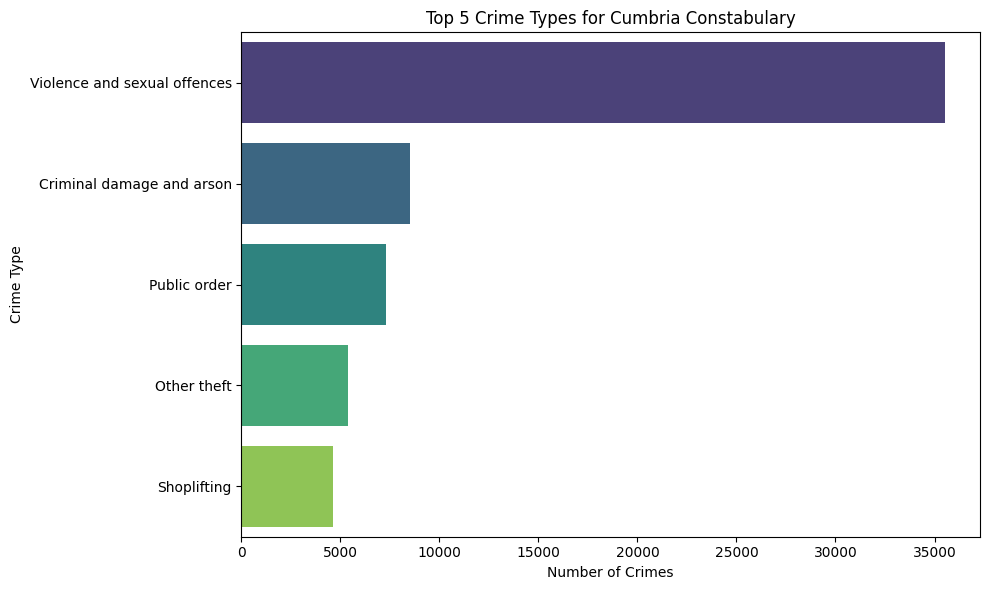

In [ ]:
for authority, top_crime_types_df in top_crime_types_by_authority.items():
    top_crime_types_pd = top_crime_types_df.toPandas()

    plt.figure(figsize=(10, 6))
    sns.barplot(x='count', y='Crime type', data=top_crime_types_pd, palette='viridis', hue='Crime type', legend=False)
    plt.title(f'Top 5 Crime Types for {authority}')
    plt.xlabel('Number of Crimes')
    plt.ylabel('Crime Type')
    plt.tight_layout()
    plt.show()

### Crime type within top 10 Lower Super Output Areas (LSOAs)

In [ ]:
#Filter out NULL LSOA names and get the actual top 10 LSOA names from the previous analysis
top_10_lsoa_names = [row['LSOA name'] for row in top_10_lsoa_crimes_cleaned.collect() if row['LSOA name'] is not None]

# Filter the BCLN_Crime_cleaned df for these top LSOAs and non-null LSOA names
filtered_lsoa_crime_data = BCLN_Crime_cleaned.filter(
    (col("LSOA name").isin(top_10_lsoa_names)) & (col("LSOA name").isNotNull()))

# Group by LSOA name and Crime type, then count
lsoa_crime_type_counts = filtered_lsoa_crime_data.groupBy("LSOA name", "Crime type").count()

#Create a Spark Window partitioned by LSOA name and ordered by count in descending
window_spec = Window.partitionBy("LSOA name").orderBy(col("count").desc())

# Apply a row number to each crime type within each LSOA
lsoa_crime_type_ranked = lsoa_crime_type_counts.withColumn("row_num", row_number().over(window_spec))

#Filter the results to keep only the top 5 crime type
top_5_crime_types_per_lsoa = lsoa_crime_type_ranked.filter(col("row_num") <= 5).drop("row_num")

#Store results in dictionary
top_crime_types_by_lsoa = {}
for lsoa_name in top_10_lsoa_names:
    df_lsoa = top_5_crime_types_per_lsoa.filter(col("LSOA name") == lsoa_name).toPandas()
    top_crime_types_by_lsoa[lsoa_name] = df_lsoa

# top 5 crime types
if top_10_lsoa_names:
    print(f"Top 5 Crime Types for {top_10_lsoa_names[0]}:\n")
    print(top_crime_types_by_lsoa[top_10_lsoa_names[0]])
else:
    print("No top LSOAs found after filtering NULL values.")

Top 5 Crime Types for Leicester 041E:

        LSOA name                    Crime type  count
0  Leicester 041E  Violence and sexual offences   2468
1  Leicester 041E                   Shoplifting   1632
2  Leicester 041E                  Public order   1208
3  Leicester 041E                   Other theft    835
4  Leicester 041E     Criminal damage and arson    391


## Visualization

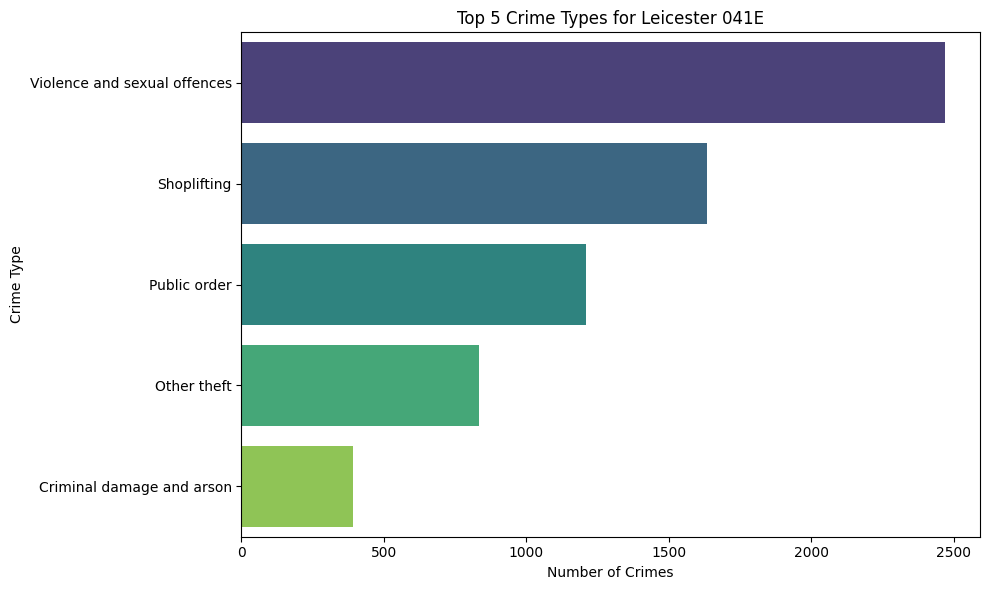

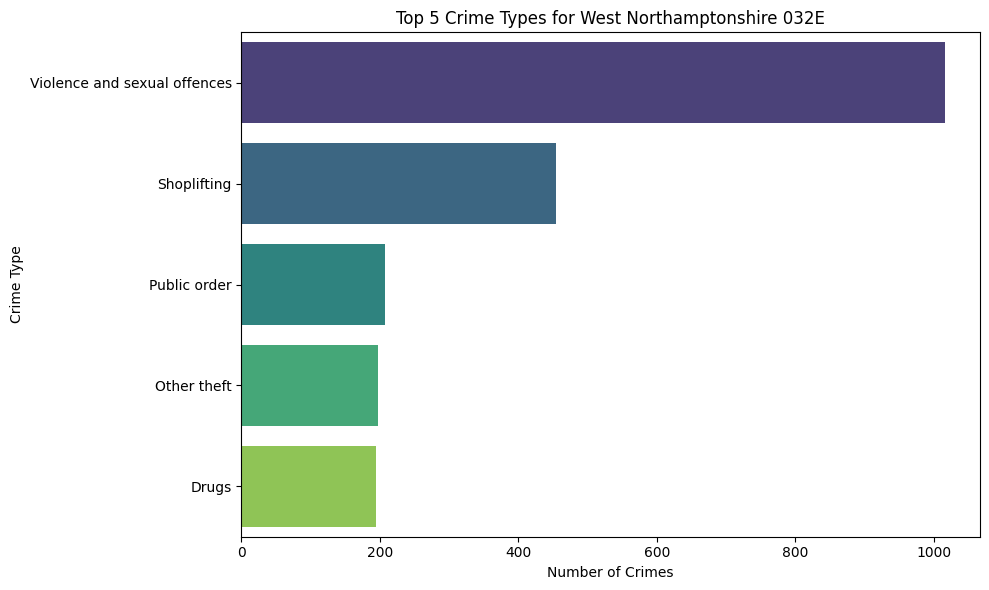

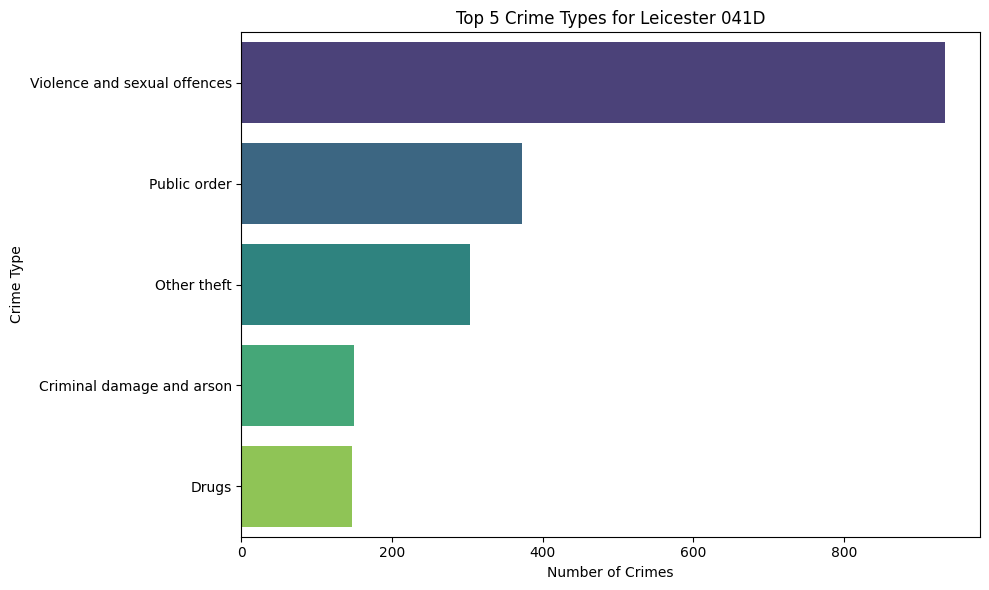

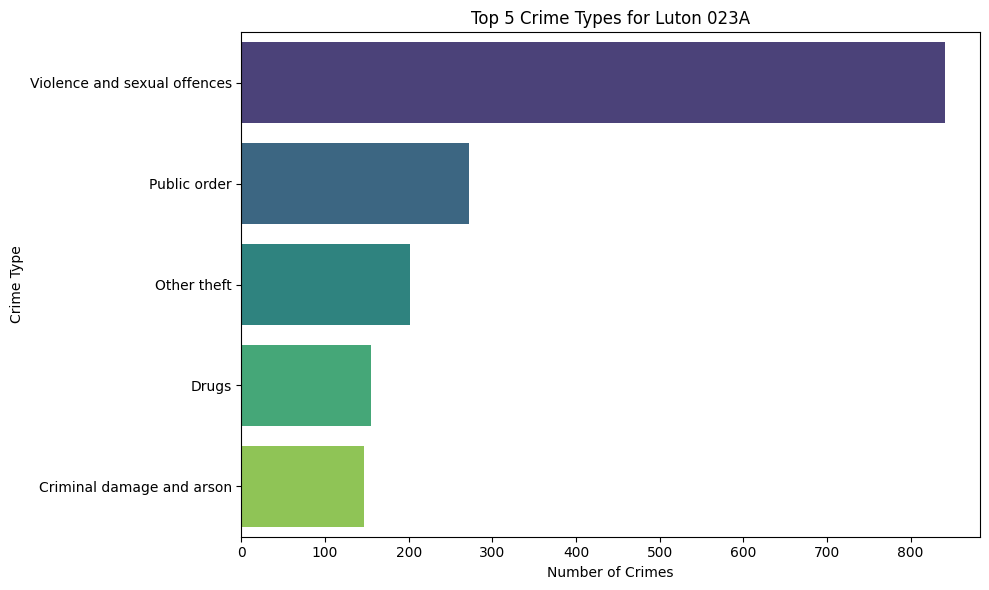

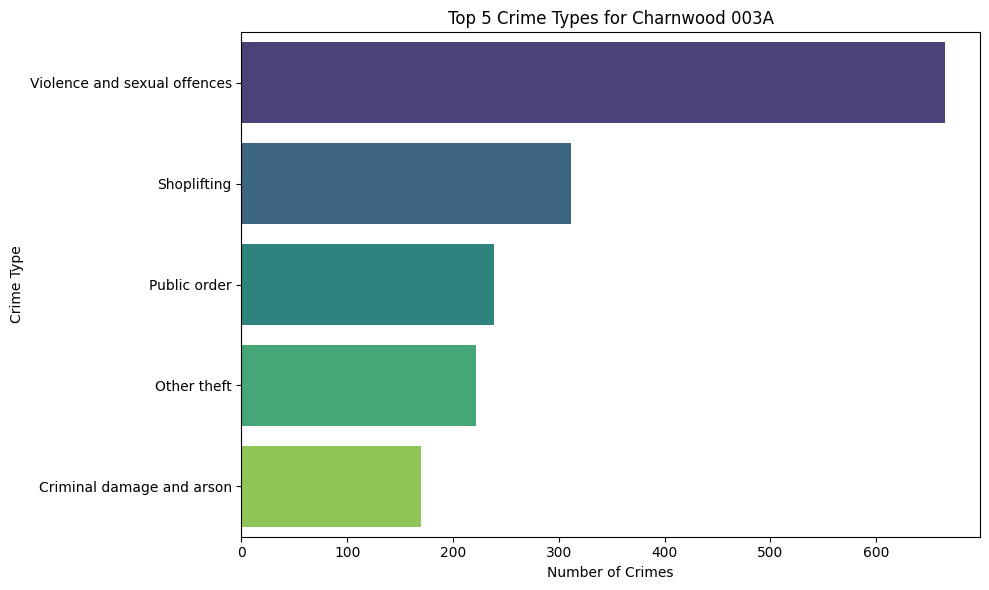

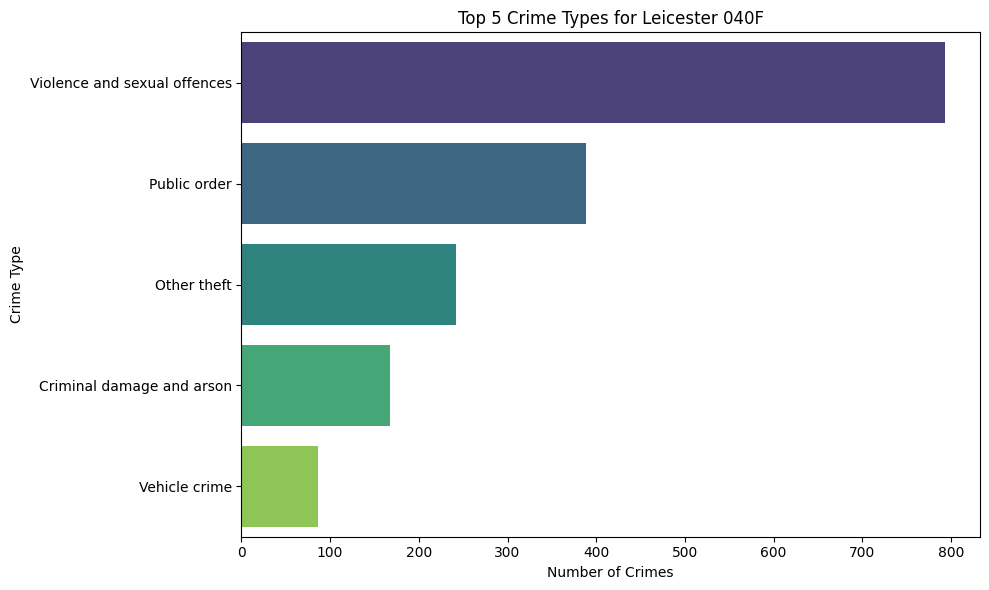

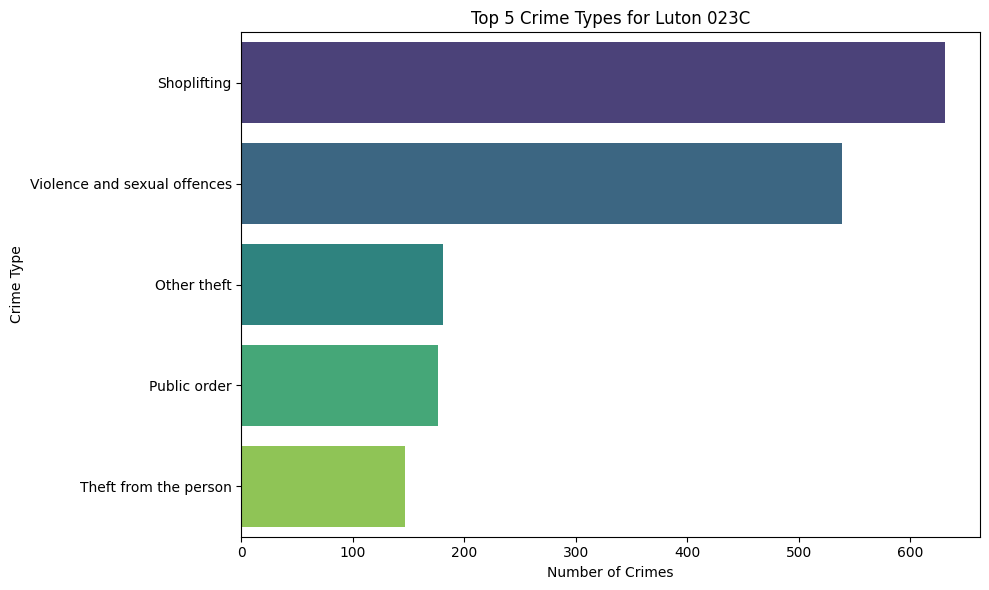

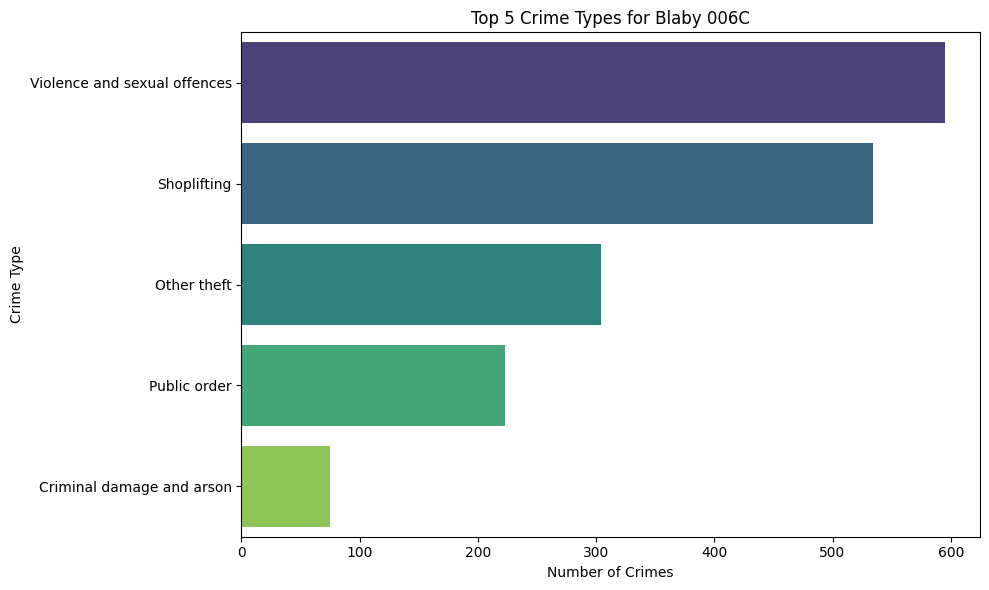

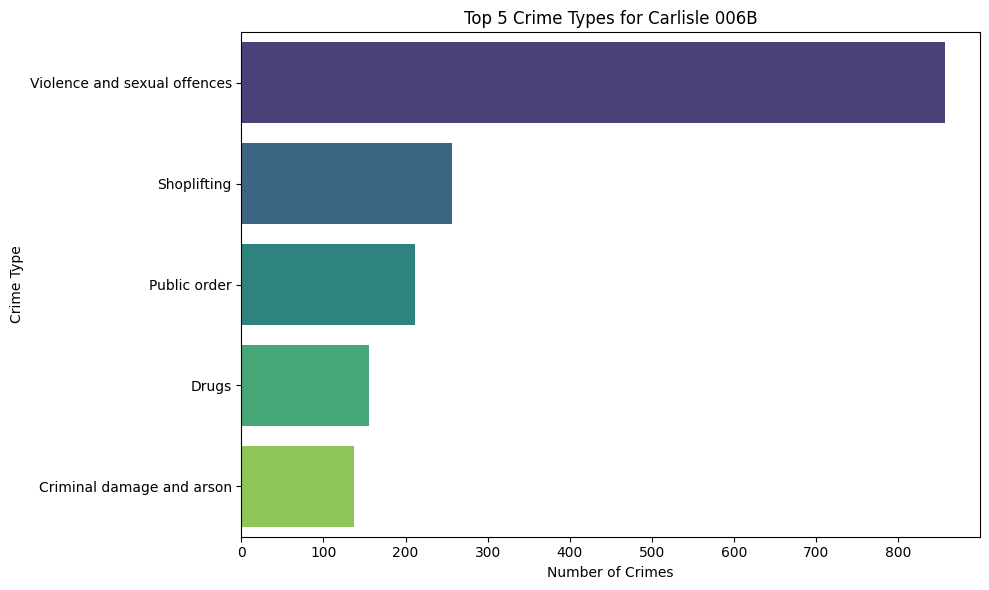

In [ ]:
for lsoa_name, df_lsoa in top_crime_types_by_lsoa.items():
    plt.figure(figsize=(10, 6))
    sns.barplot(x='count', y='Crime type', data=df_lsoa, palette='viridis', hue='Crime type', legend=False)
    plt.title(f'Top 5 Crime Types for {lsoa_name}')
    plt.xlabel('Number of Crimes')
    plt.ylabel('Crime Type')
    plt.tight_layout()
    plt.show()